# Tutorial 3g: Model Glass and Continuous Nd/Vd Optimization

Tutorial 3e optimized the glasses with `GlassExpert`, which is a *categorical* search over a fixed list of catalogue glasses. This tutorial takes the complementary route:

1. **Model glass.** Every lens is converted to an `optiland.materials.ModelMaterial`: a Buchdahl polynomial fitted to the glass descriptors `Nd` (index at the d-line) and `Vd` (Abbe number). Both descriptors become ordinary continuous variables, so the optimizer is free to invent glasses that no catalogue contains.
2. **Snap to reality.** Each fictitious glass is projected back onto a real catalogue glass with `optiland.materials.find_closest_glass`, and the geometry is re-optimized.

The starting system is the same deliberately poor six-lens design used in Tutorial 3e.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import optiland.backend as be
from optiland import optic, optimization
from optiland.materials import (
    Material,
    MaterialCatalog,
    OptilandMaterialWarning,
    find_closest_glass,
    get_nd_vd,
    glasses_selection,
)
from optiland.optimization import HistoryObserver, minimize

# Air has no dispersion, so its Abbe number is infinite: querying the whole
# surface group divides by zero and NumPy raises a harmless RuntimeWarning.
warnings.filterwarnings("ignore", message="divide by zero encountered in scalar divide")
warnings.filterwarnings(
    "ignore", message="invalid value encountered in scalar divide"
)

# find_closest_glass resolves every candidate by bare name, so glasses that
# exist in several catalogues warn once each.
warnings.filterwarnings("ignore", category=OptilandMaterialWarning)

# Some trial designs during optimisation vignette an entire field. Optiland
# scores them as very poor, but NumPy warns about the empty ray bundle first.
warnings.filterwarnings("ignore", message="Mean of empty slice")

## The starting point

The design is intentionally mediocre: six identical collimating lenses made of N-BK7, with radii of 1000 mm and no attempt at colour correction.

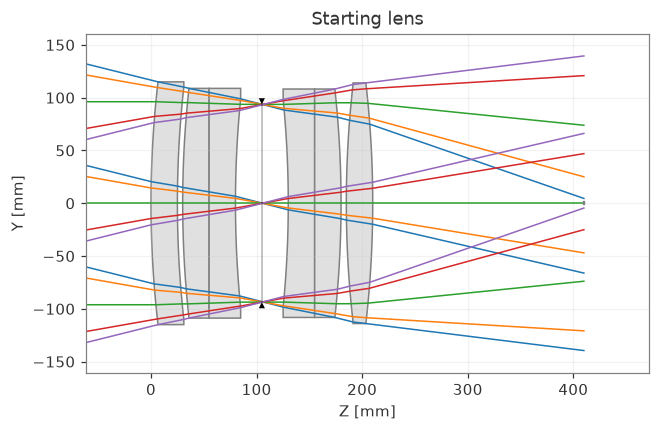

In [2]:
D_LINE = 0.5875618  # [um]
GLASS_SURFACES = (1, 3, 4, 7, 8, 10)
TARGET_FOCAL_LENGTH = 100  # [mm]


class SixLensesStartPoint(optic.Optic):
    """A 6 lens design with very poor quality meant to be optimized."""

    def __init__(self):
        super().__init__()

        self.surfaces.add(index=0, radius=be.inf, thickness=be.inf)
        self.surfaces.add(index=1, radius=1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=2, radius=1000, thickness=5.0)
        self.surfaces.add(index=3, radius=1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=4, radius=be.inf, thickness=25, material="N-BK7")
        self.surfaces.add(index=5, radius=1000, thickness=25)
        self.surfaces.add(index=6, radius=be.inf, thickness=25.0, is_stop=True)
        self.surfaces.add(index=7, radius=-1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=8, radius=be.inf, thickness=25, material="N-BK7")
        self.surfaces.add(index=9, radius=-1000, thickness=5.0)
        self.surfaces.add(index=10, radius=1000, thickness=25, material="N-BK7")
        self.surfaces.add(index=11, radius=-1000, thickness=200)
        self.surfaces.add(index=12)

        self.set_aperture(aperture_type="imageFNO", value=5)
        self.fields.set_type(field_type="angle")

        self.fields.add(y=-14)
        self.fields.add(y=-10)
        self.fields.add(y=0)
        self.fields.add(y=10)
        self.fields.add(y=14)

        self.wavelengths.add(value=0.4861)
        self.wavelengths.add(value=0.5876, is_primary=True)
        self.wavelengths.add(value=0.6563)


lens = SixLensesStartPoint()
lens.draw(title="Starting lens")

In [3]:
lens.info()

╒════╤═══════════════╤═══════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment   │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪═══════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │           │      inf │         inf │ Air        │       0 │        116.634  │
│  1 │ Standard      │           │     1000 │          25 │ N-BK7      │       0 │        116.634  │
│  2 │ Standard      │           │     1000 │           5 │ Air        │       0 │        111.531  │
│  3 │ Standard      │           │     1000 │          25 │ N-BK7      │       0 │        110.271  │
│  4 │ Planar        │           │      inf │          25 │ N-BK7      │       0 │        105.179  │
│  5 │ Standard      │           │     1000 │          25 │ Air        │       0 │        100.087  │
│  6 │ Stop - Planar │           │      inf │          25 │ Air        │       0 │         

## Step 1 - from catalogue glass to model glass

A `ModelMaterial` is defined by four descriptors: `Nd`, `Vd`, `dPgF` (the partial-dispersion deviation from the normal line) and, for infrared work, a reference partial dispersion `P_ref` at `lambda_ref`. Optiland can build one from any existing material:

```python
lens.updater.set_index(value, surface_number)   # wavelength=None
```

With `wavelength=None`, `set_index` reads the `Nd`, `Vd` and `dPgF` of the current glass and rebuilds the surface material as a `ModelMaterial`. The Buchdahl fit is anchored on the d, F, C and g lines, so the model glass reproduces the original catalogue glass very closely.

The model is only valid for `1.0 < Nd < 3.0` and `10 < Vd < 100`, which we will respect when setting the variable bounds.

In [4]:
def nd_vd(material):
    """Return Nd and Vd of a catalogue or model glass as plain floats."""
    nd = float(np.ravel(be.to_numpy(material.n(D_LINE)))[0])
    vd = float(np.ravel(be.to_numpy(material.abbe()))[0])
    return nd, vd


before = {k: nd_vd(lens.surfaces[k].material_post) for k in GLASS_SURFACES}

for surface_number in GLASS_SURFACES:
    lens.updater.set_index(before[surface_number][0], surface_number)

print(f"{'surface':>8}{'material':>15}{'Nd':>10}{'Vd':>9}")
for k in GLASS_SURFACES:
    material = lens.surfaces[k].material_post
    nd, vd = nd_vd(material)
    print(f"{k:>8}{type(material).__name__:>15}{nd:>10.5f}{vd:>9.3f}")

 surface       material        Nd       Vd
       1  ModelMaterial   1.51680   64.167
       3  ModelMaterial   1.51680   64.167
       4  ModelMaterial   1.51680   64.167
       7  ModelMaterial   1.51680   64.167
       8  ModelMaterial   1.51680   64.167
      10  ModelMaterial   1.51680   64.167


## Merit function

Tutorial 3e evaluated the spot size only at the primary wavelength, so the merit function had no information about colour. Here the focal length and the RMS spot size are evaluated at **all three wavelengths**: an optimizer can only move `Vd` if the merit function sees chromatic aberration.

- `real_y_intercept_lcs` on the image plane keeps the focal length at 100 mm for five field points, at every wavelength (this is the axial colour constraint).
- `rms_spot_size` with 16 uniform rays per field minimises the spot at every field and wavelength.

Both sets of operands are wrapped in a `make_problem` helper so that the same merit can be rebuilt after the glasses are replaced.

In [5]:
def make_problem(lens, optimize_glass=True):
    """Build the merit function, the geometric variables and (optionally) glass variables."""
    problem = optimization.OptimizationProblem()

    # Focal length at every field and every wavelength.
    for wavelength in lens.wavelengths:
        for k, hy in enumerate([-1, -0.714, 0, 0.714, 1]):
            input_data = {
                "optic": lens,
                "surface_number": 12,
                "Hx": 0,
                "Hy": hy,
                "Px": 0,
                "Py": 0,
                "wavelength": wavelength.value,
            }
            problem.add_operand(
                operand_type="real_y_intercept_lcs",
                target=TARGET_FOCAL_LENGTH
                * be.tan(be.deg2rad(lens.fields.y_fields[k])),
                weight=1,
                input_data=input_data,
            )

    # RMS spot size at every field and every wavelength.
    for field in lens.fields.get_field_coords():
        for wavelength in lens.wavelengths:
            input_data = {
                "optic": lens,
                "surface_number": 12,
                "Hx": field[0],
                "Hy": field[1],
                "num_rays": 16,
                "wavelength": wavelength.value,
                "distribution": "uniform",
            }
            problem.add_operand(
                operand_type="rms_spot_size",
                target=0.0,
                weight=10,
                input_data=input_data,
            )

    # Curvatures.
    for surface_number in (1, 2, 3, 5, 7, 9, 10, 11):
        problem.add_variable(
            lens, "radius", surface_number=surface_number, min_val=-500, max_val=500
        )

    # Thicknesses.
    thickness_bounds = {
        1: (8, 20),
        2: (0.4, 5),
        3: (8, 20),
        4: (3, 10),
        5: (10, 20),
        6: (10, 20),
        7: (3, 20),
        8: (8, 20),
        9: (0.4, 5),
        10: (6, 20),
        11: (20, 45),
    }
    for surface_number, (lo, hi) in thickness_bounds.items():
        problem.add_variable(
            lens, "thickness", surface_number=surface_number, min_val=lo, max_val=hi
        )

    # Glass: index at the d-line and Abbe number, both continuous.
    if optimize_glass:
        for surface_number in GLASS_SURFACES:
            problem.add_variable(
                lens,
                "index",
                surface_number=surface_number,
                wavelength=None,
                min_val=1.40,
                max_val=2.00,
            )
            problem.add_variable(
                lens,
                "abbe",
                surface_number=surface_number,
                min_val=20,
                max_val=90,
            )

    return problem


problem = make_problem(lens, optimize_glass=True)
merit_start = problem.sum_squared()
print(f"variables: {len(problem.variables)}   starting merit: {merit_start:.3e}")
problem.info()

variables: 31   starting merit: 3.935e+06
╒════╤════════════════════════╤═══════════════════╕
│    │   Merit Function Value │   Improvement (%) │
╞════╪════════════════════════╪═══════════════════╡
│  0 │            3.93457e+06 │                 0 │
╘════╧════════════════════════╧═══════════════════╛
╒════╤══════════════════════╤══════════╤══════════════╤══════════════╤══════════╤═══════════════╤═════════╤═════════╤════════════════╕
│    │ Operand Type         │   Target │ Min. Bound   │ Max. Bound   │   Weight │   Eff. Weight │   Value │   Delta │   Contrib. [%] │
╞════╪══════════════════════╪══════════╪══════════════╪══════════════╪══════════╪═══════════════╪═════════╪═════════╪════════════════╡
│  0 │ real y intercept lcs │  -24.933 │              │              │        1 │             1 │ -66.102 │ -41.169 │           0.04 │
│  1 │ real y intercept lcs │  -17.633 │              │              │        1 │             1 │ -46.942 │ -29.31  │           0.02 │
│  2 │ real y intercept

## Optimizing Nd and Vd continuously

The `index` variable moves `Nd` (it calls `updater.set_index`, which rebuilds the `ModelMaterial` with the new index while keeping `Vd` and `dPgF`). The `abbe` variable moves `Vd` through `updater.set_abbe`, which keeps `Nd` and `dPgF`.

`dPgF` is deliberately left at its starting value: the six model glasses therefore share the dispersion curve shape of N-BK7 and differ only in `Nd` and `Vd`.

The problem is fully continuous, so Optiland's native damped least squares (`"dls"`) can solve it.

In [6]:
history = HistoryObserver()
result = minimize(problem, "dls", observers=[history])

merit_continuous = problem.sum_squared()
print(f"stop reason: {result.stop_reason}")
print(f"merit: {merit_continuous:.3f}   residual evaluations: {result.n_evals}")

stop reason: `ftol` termination condition is satisfied.
merit: 10.897   residual evaluations: 361


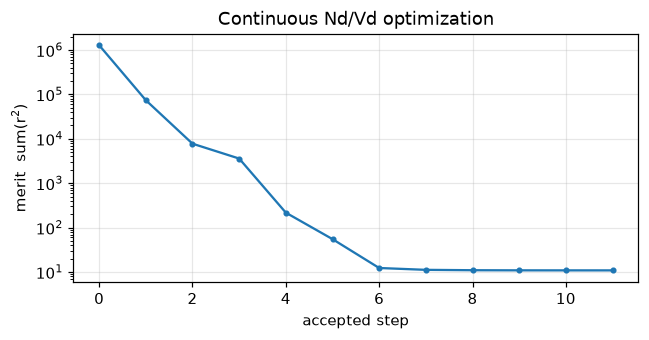

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogy(
    [r["iteration"] for r in history.records],
    [r["value"] for r in history.records],
    marker="o",
    ms=3,
)
ax.set_xlabel("accepted step")
ax.set_ylabel("merit  sum(r$^2$)")
ax.set_title("Continuous Nd/Vd optimization")
ax.grid(alpha=0.3)
fig.tight_layout()

 surface        Nd       Vd      dPgF
       1   1.86841   66.770  -0.00094
       3   1.43086   81.927  -0.00094
       4   1.40007   50.845  -0.00094
       7   1.42869   54.455  -0.00094
       8   1.42838   77.258  -0.00094
      10   1.96628   83.475  -0.00094


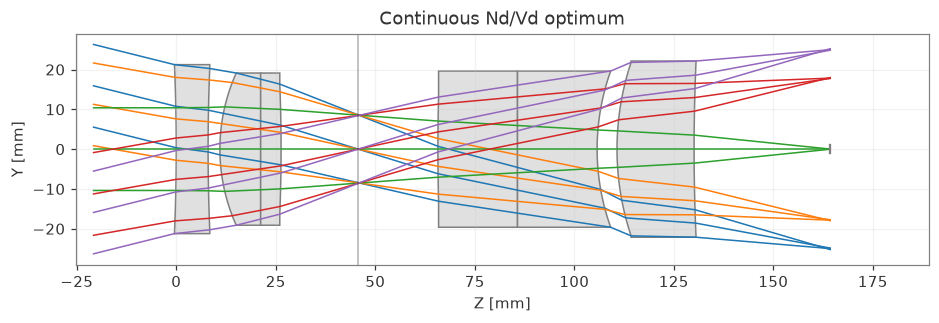

In [8]:
print(f"{'surface':>8}{'Nd':>10}{'Vd':>9}{'dPgF':>10}")
for k in GLASS_SURFACES:
    material = lens.surfaces[k].material_post
    print(f"{k:>8}{material.nd:>10.5f}{material.vd:>9.3f}{material.dPgf:>10.5f}")

lens.draw(title="Continuous Nd/Vd optimum")

## Step 2 - snapping back to real glass

The optimum above is made of fictitious glasses. `find_closest_glass((Nd, Vd), catalog)` returns the name of the catalogue glass whose `(Nd, Vd)` is closest to the target, using the squared Euclidean distance in that plane.

Two practical points:

- The distance is **not normalised**: `Nd` spans roughly 0.3 index units while `Vd` spans roughly 70, so the metric is dominated by `Vd`. A model glass can therefore be matched to a real glass with a very different index - watch the `dist` column below.
- `find_closest_glass` takes plain names, so we keep a name -> catalogue map and instantiate every replacement with `Material(name, catalog=...)` to avoid ambiguous matches between catalogues.

The candidate list is restricted to Schott and Ohara glasses that transmit the full 0.4-0.7 um band.

In [9]:
catalogs = ("schott", "ohara")

catalog_of = {}
for catalog in catalogs:
    for name in MaterialCatalog(catalog).list():
        catalog_of.setdefault(name, catalog)

candidates = glasses_selection(0.4, 0.7, catalogs=list(catalogs))
print(f"{len(candidates)} candidate glasses from {catalogs}")

564 candidate glasses from ('schott', 'ohara')


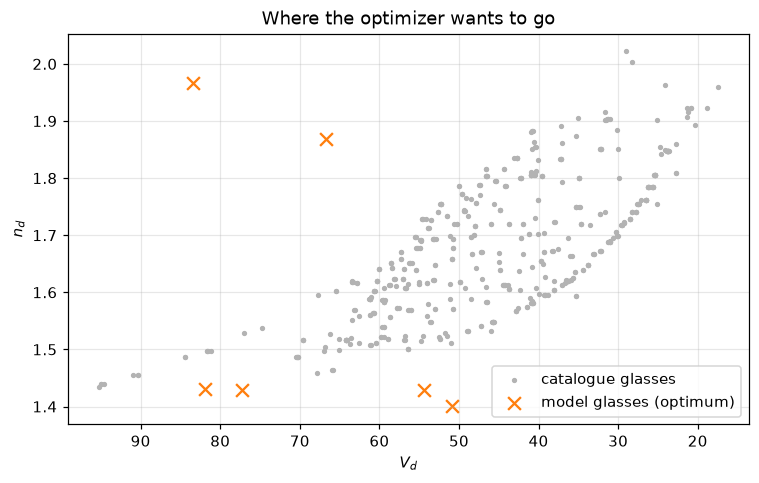

In [10]:
glass_map = {name: get_nd_vd(name) for name in candidates}
# Glass entries without Nd/Vd in their data file come back as (0, 0); drop them.
points = np.array([pair for pair in glass_map.values() if pair[0] > 0.0])
model_points = np.array([nd_vd(lens.surfaces[k].material_post) for k in GLASS_SURFACES])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(points[:, 1], points[:, 0], s=6, c="0.7", label="catalogue glasses")
ax.scatter(
    model_points[:, 1],
    model_points[:, 0],
    marker="x",
    s=70,
    c="tab:orange",
    label="model glasses (optimum)",
)
ax.invert_xaxis()
ax.set_xlabel("$V_d$")
ax.set_ylabel("$n_d$")
ax.set_title("Where the optimizer wants to go")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()

In [11]:
print(
    f"{'surface':>8}{'model Nd':>10}{'model Vd':>10}"
    f"{'glass':>14}{'Nd':>9}{'Vd':>9}{'dist':>8}"
)

for surface_number in GLASS_SURFACES:
    material = lens.surfaces[surface_number].material_post
    nd, vd = material.nd, material.vd
    glass = find_closest_glass((nd, vd), candidates)
    replacement = Material(glass, catalog=catalog_of[glass])
    new_nd, new_vd = nd_vd(replacement)
    distance = ((nd - new_nd) ** 2 + (vd - new_vd) ** 2) ** 0.5
    lens.updater.set_material(replacement, surface_number)
    print(
        f"{surface_number:>8}{nd:>10.5f}{vd:>10.3f}"
        f"{glass:>14}{new_nd:>9.5f}{new_vd:>9.3f}{distance:>8.3f}"
    )

problem_real = make_problem(lens, optimize_glass=False)
merit_snapped = problem_real.sum_squared()
print(f"\nmerit after snapping: {merit_snapped:.1f}")

 surface  model Nd  model Vd         glass       Nd       Vd    dist
       1   1.86841    66.770         BSL21  1.50378   66.815   0.367
       3   1.43086    81.927         FPL51  1.49700   81.615   0.319
       4   1.40007    50.845        S-BAL2  1.57099   50.800   0.177
       7   1.42869    54.455      D263TECO  1.52330   54.517   0.113
       8   1.42838    77.258        N-PK51  1.52855   76.976   0.300
      10   1.96628    83.475        N-FK51  1.48656   84.468   1.103

merit after snapping: 9883.2


## Re-optimizing the geometry

Substituting real glasses changes the optical power and the chromatic correction, so the merit function jumps. Only the radii and thicknesses are left as variables here; the glasses are now fixed catalogue materials.

stop reason: `ftol` termination condition is satisfied.
merit: 24.505


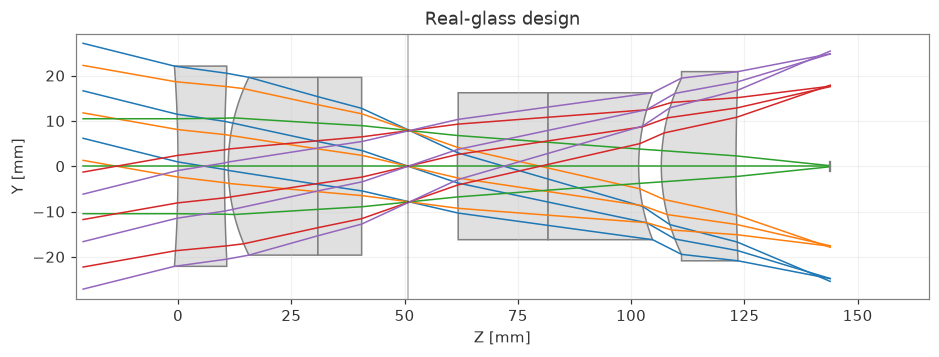

In [12]:
result_real = minimize(problem_real, "dls")

merit_final = problem_real.sum_squared()
print(f"stop reason: {result_real.stop_reason}")
print(f"merit: {merit_final:.3f}")

lens.draw(title="Real-glass design")

## Summary

The two-stage workflow is a fast alternative to a categorical glass search: the continuous `Nd`/`Vd` optimum is found with a handful of damped-least-squares steps, and only the final snapping step touches the catalogue.

Keep the following limitations in mind:

- **The model glasses are fictitious.** Only `Nd` and `Vd` are free here; `dPgF` was frozen at the starting value, and the family of glasses the optimizer can reach is therefore narrower than the real glass map. Making `dPgF` a variable as well would require a partial-dispersion operand.
- **`find_closest_glass` is an unweighted nearest neighbour.** Because `Vd` is numerically much larger than `Nd`, the match is essentially "same Abbe number, any index". If index accuracy matters more, restrict the candidate list, or build a custom weighted criterion (`get_neighbour_glasses` reserves `w_nd`/`w_vd` weights for this).
- **Re-optimisation is mandatory.** Snapping alone can degrade the merit function by orders of magnitude; the final local optimisation recovers most of the performance.
- **Tutorial 3e is the complementary tool.** `GlassExpert` searches the catalogue directly and can also explore glasses far from the continuous optimum, at the cost of many more merit-function evaluations.

In [13]:
print(f"{'stage':<32}{'merit':>14}")
print(f"{'starting design':<32}{merit_start:>14.3e}")
print(f"{'continuous Nd/Vd optimum':<32}{merit_continuous:>14.3f}")
print(f"{'after snapping to real glass':<32}{merit_snapped:>14.1f}")
print(f"{'after re-optimizing geometry':<32}{merit_final:>14.3f}")

stage                                    merit
starting design                      3.935e+06
continuous Nd/Vd optimum                10.897
after snapping to real glass            9883.2
after re-optimizing geometry            24.505
